# Model Evaluation
### Data Science Core Concepts 101 — by Yunhan Jin

Training a model is only half the work — evaluating it correctly is what separates good models from bad ones in production. This notebook covers:
- Regression and classification metrics
- Overfitting vs underfitting
- Validation strategies

---

## Section 1: Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold,
    TimeSeriesSplit, validation_curve, learning_curve
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, classification_report,
    precision_score, recall_score, f1_score
)
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
n = 500
neighborhoods = ['Downtown', 'Midtown', 'Uptown', 'Suburbs', 'Riverside'] * (n // 5)
conditions    = ['Poor', 'Fair', 'Good', 'Excellent']

df = pd.DataFrame({
    'sqft':         np.random.normal(1800, 400, n).astype(int).clip(600, 4000),
    'bedrooms':     np.random.choice([2, 3, 4, 5], n, p=[0.2, 0.4, 0.3, 0.1]),
    'neighborhood': neighborhoods,
    'condition':    np.random.choice(conditions, n, p=[0.1, 0.2, 0.5, 0.2]),
    'year_built':   np.random.randint(1960, 2020, n),
    'has_garage':   np.random.choice([True, False], n, p=[0.7, 0.3]),
    'listing_date': pd.date_range('2020-01-01', periods=n, freq='D'),
})

hood_price = {'Downtown': 1.3, 'Midtown': 1.1, 'Uptown': 1.0, 'Suburbs': 0.9, 'Riverside': 1.05}
cond_price  = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}

df['price'] = (
    80000
    + df['sqft'] * 120
    + df['bedrooms'] * 8000
    + df['condition'].map(cond_price) * 15000
    + df['has_garage'].astype(int) * 12000
    + np.random.normal(0, 20000, n)
) * df['neighborhood'].map(hood_price)
df['price']             = df['price'].clip(100000, 1000000).astype(int)
df['condition_encoded'] = df['condition'].map({'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3})
df = pd.get_dummies(df, columns=['neighborhood'], drop_first=True)
df['has_garage']        = df['has_garage'].astype(int)
df['house_age']         = 2024 - df['year_built']
df['listing_month']     = df['listing_date'].dt.month
df['is_summer']         = df['listing_month'].isin([6, 7, 8]).astype(int)
df['log_price']         = np.log(df['price'])
df['high_value']        = (df['price'] > df['price'].median()).astype(int)

feature_cols = [
    'sqft', 'bedrooms', 'condition_encoded', 'has_garage', 'house_age', 'is_summer',
    'neighborhood_Midtown', 'neighborhood_Riverside', 'neighborhood_Suburbs', 'neighborhood_Uptown'
]

X       = df[feature_cols]
y_reg   = df['log_price']
y_clf   = df['high_value']

X_train, X_test, y_reg_train, y_reg_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)
_, _,           y_clf_train, y_clf_test  = train_test_split(X, y_clf, test_size=0.2, random_state=42)

# Train models
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_reg_train)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_clf_train)

y_reg_pred = rf_reg.predict(X_test)
y_clf_pred = rf_clf.predict(X_test)

print('Models trained. Ready for evaluation.')

Models trained. Ready for evaluation.


---
## Section 2: Regression Metrics

| Metric | Formula | Units | Notes |
|--------|---------|-------|-------|
| MAE | mean(|y − ŷ|) | same as y | interpretable, robust to outliers |
| RMSE | √mean((y − ŷ)²) | same as y | penalizes large errors more than MAE |
| R² | 1 − SS_res/SS_tot | unitless [0, 1] | proportion of variance explained |

In [2]:
mae  = mean_absolute_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred))
r2   = r2_score(y_reg_test, y_reg_pred)

print('Random Forest Regressor — Test Set')
print(f'  MAE:  {mae:.4f}   (log scale — {np.exp(mae):.1f}x multiplicative error)')
print(f'  RMSE: {rmse:.4f}')
print(f'  R²:   {r2:.4f}')

Random Forest Regressor — Test Set
  MAE:  0.0619   (log scale — 1.1x multiplicative error)
  RMSE: 0.0787
  R²:   0.8497


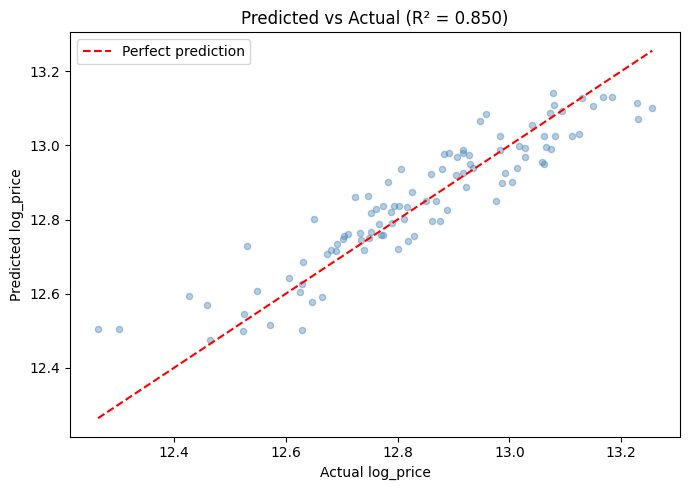

In [3]:
# Predicted vs actual plot
plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, y_reg_pred, alpha=0.4, s=20, color='steelblue')
min_val = min(y_reg_test.min(), y_reg_pred.min())
max_val = max(y_reg_test.max(), y_reg_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Perfect prediction')
plt.xlabel('Actual log_price')
plt.ylabel('Predicted log_price')
plt.title(f'Predicted vs Actual (R² = {r2:.3f})')
plt.legend()
plt.tight_layout()
plt.show()

---
## Section 3: Classification Metrics

**Accuracy** alone is insufficient — especially with class imbalance. A model that always predicts the majority class gets high accuracy but is useless.

From the confusion matrix (TP, FP, TN, FN):
- **Precision** = TP / (TP + FP) — of predicted positives, how many are correct
- **Recall** = TP / (TP + FN) — of actual positives, how many did we catch
- **F1** = 2 × (Precision × Recall) / (Precision + Recall) — harmonic mean

Use case guidance:
- Prefer **precision** when false positives are costly (spam filter — don't want to block real email)
- Prefer **recall** when false negatives are costly (cancer screening — don't want to miss a case)

In [4]:
print('Random Forest Classifier — Test Set')
print(f'  Accuracy:  {(y_clf_pred == y_clf_test).mean():.4f}')
print(f'  Precision: {precision_score(y_clf_test, y_clf_pred):.4f}')
print(f'  Recall:    {recall_score(y_clf_test, y_clf_pred):.4f}')
print(f'  F1:        {f1_score(y_clf_test, y_clf_pred):.4f}')
print()
print('Classification Report:')
print(classification_report(y_clf_test, y_clf_pred, target_names=['low_value', 'high_value']))

Random Forest Classifier — Test Set
  Accuracy:  0.8500
  Precision: 0.8182
  Recall:    0.9000
  F1:        0.8571

Classification Report:
              precision    recall  f1-score   support

   low_value       0.89      0.80      0.84        50
  high_value       0.82      0.90      0.86        50

    accuracy                           0.85       100
   macro avg       0.85      0.85      0.85       100
weighted avg       0.85      0.85      0.85       100



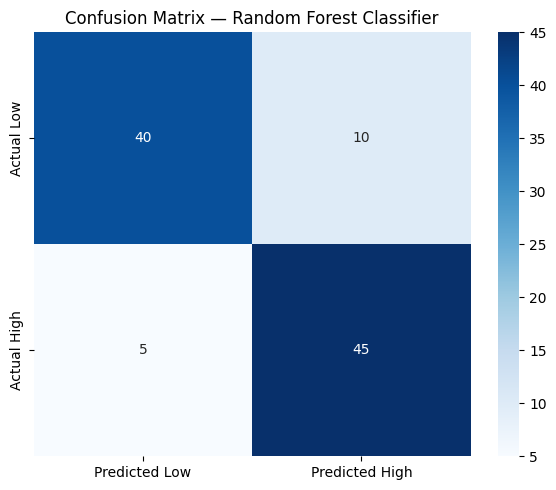

In [5]:
# Confusion matrix
cm = confusion_matrix(y_clf_test, y_clf_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicted Low', 'Predicted High'],
    yticklabels=['Actual Low', 'Actual High']
)
plt.title('Confusion Matrix — Random Forest Classifier')
plt.tight_layout()
plt.show()

---
## Section 4: Overfitting vs Underfitting

- **Underfitting** (high bias): model is too simple — poor performance on both train and test
- **Overfitting** (high variance): model is too complex — great on train, poor on test
- **Good fit**: low train and test error, small gap between them

**Validation curve**: plots train and CV scores against model complexity (e.g. `max_depth` for a decision tree). Shows where the model transitions from underfitting to overfitting.

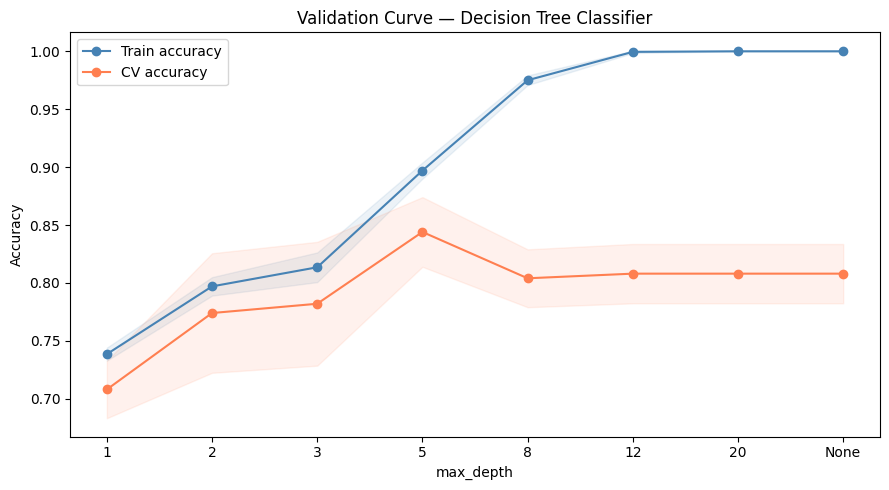

In [6]:
depths = [1, 2, 3, 5, 8, 12, 20, None]

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=42),
    X, y_clf,
    param_name='max_depth',
    param_range=depths,
    cv=5,
    scoring='accuracy'
)

depth_labels = [str(d) if d is not None else 'None' for d in depths]
train_mean = train_scores.mean(axis=1)
val_mean   = val_scores.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(depth_labels, train_mean, marker='o', label='Train accuracy', color='steelblue')
plt.plot(depth_labels, val_mean,   marker='o', label='CV accuracy',    color='coral')
plt.fill_between(depth_labels, train_mean - train_scores.std(1), train_mean + train_scores.std(1), alpha=0.1, color='steelblue')
plt.fill_between(depth_labels, val_mean   - val_scores.std(1),   val_mean   + val_scores.std(1),   alpha=0.1, color='coral')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Validation Curve — Decision Tree Classifier')
plt.legend()
plt.tight_layout()
plt.show()

### 4.1 Learning Curve
A **learning curve** shows how model performance changes as training set size grows. Helps diagnose whether you need more data or a better model:
- If both curves plateau and are close → good fit
- If both curves plateau high → underfitting (need more complexity)
- If large gap between curves → overfitting (need more data or regularization)

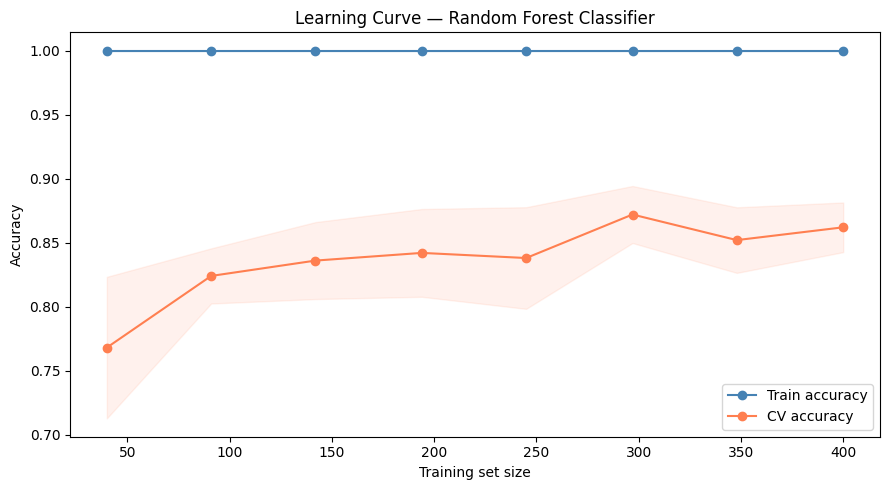

In [7]:
train_sizes, train_scores_lc, val_scores_lc = learning_curve(
    RandomForestClassifier(n_estimators=50, random_state=42),
    X, y_clf,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring='accuracy'
)

train_mean_lc = train_scores_lc.mean(axis=1)
val_mean_lc   = val_scores_lc.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean_lc, marker='o', label='Train accuracy', color='steelblue')
plt.plot(train_sizes, val_mean_lc,   marker='o', label='CV accuracy',    color='coral')
plt.fill_between(train_sizes, train_mean_lc - train_scores_lc.std(1), train_mean_lc + train_scores_lc.std(1), alpha=0.1, color='steelblue')
plt.fill_between(train_sizes, val_mean_lc   - val_scores_lc.std(1),   val_mean_lc   + val_scores_lc.std(1),   alpha=0.1, color='coral')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title('Learning Curve — Random Forest Classifier')
plt.legend()
plt.tight_layout()
plt.show()

---
## Section 5: Validation Strategies

| Strategy | When to use |
|----------|-------------|
| Holdout (train/test split) | Large datasets, fast iteration |
| K-Fold CV | General purpose, more reliable estimate |
| Stratified K-Fold | Classification with class imbalance — preserves class ratio in each fold |
| Time Series Split | Time series data — never use future data to predict the past |

In [8]:
# Stratified K-Fold — preserves class balance across folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skf_scores = cross_val_score(
    RandomForestClassifier(n_estimators=50, random_state=42),
    X, y_clf, cv=skf, scoring='accuracy'
)
print('Stratified K-Fold (5-fold) — Random Forest Classifier')
print(f'  Fold accuracies: {skf_scores.round(4)}')
print(f'  Mean: {skf_scores.mean():.4f} ± {skf_scores.std():.4f}')

Stratified K-Fold (5-fold) — Random Forest Classifier
  Fold accuracies: [0.85 0.84 0.89 0.87 0.84]
  Mean: 0.8580 ± 0.0194


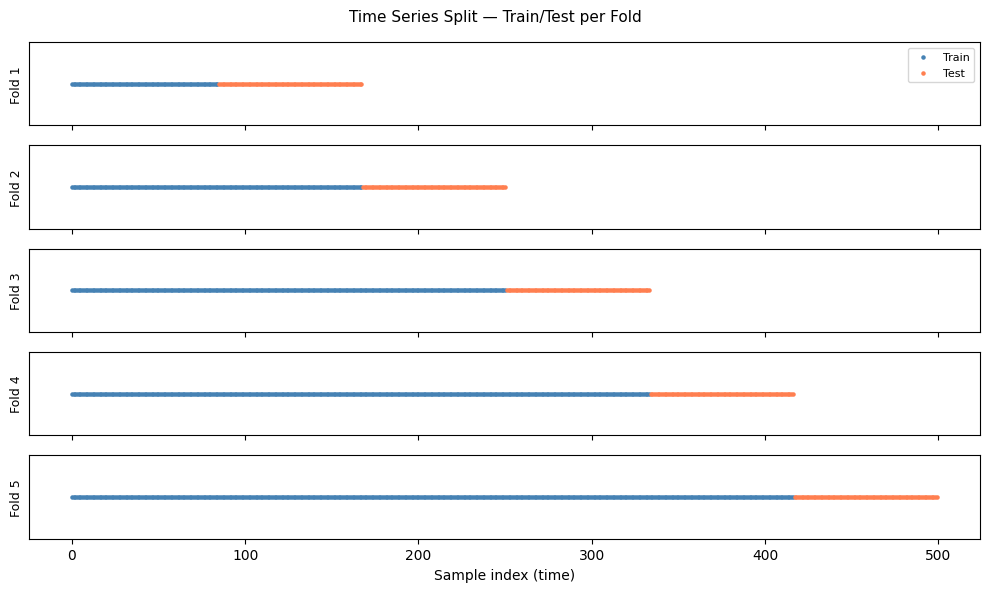

In [9]:
# Time Series Split — each fold uses only past data for training
tscv = TimeSeriesSplit(n_splits=5)

fig, axes = plt.subplots(5, 1, figsize=(10, 6), sharex=True)
for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    axes[fold].scatter(train_idx, [0]*len(train_idx), c='steelblue', s=5, label='Train')
    axes[fold].scatter(test_idx,  [0]*len(test_idx),  c='coral',     s=5, label='Test')
    axes[fold].set_ylabel(f'Fold {fold+1}', fontsize=9)
    axes[fold].set_yticks([])
    if fold == 0:
        axes[fold].legend(loc='upper right', fontsize=8)

fig.suptitle('Time Series Split — Train/Test per Fold', fontsize=11)
plt.xlabel('Sample index (time)')
plt.tight_layout()
plt.show()

---
## Section 6: Common Mistakes
- **Evaluating on train set only**: always report test or CV scores — train performance is optimistic by design.
- **Using accuracy for imbalanced classes**: a model predicting all-majority gets high accuracy but zero recall on the minority class. Use precision, recall, F1.
- **Not stratifying CV for classification**: standard K-Fold can produce folds with very different class ratios. Use `StratifiedKFold` for classification.
- **Using standard K-Fold on time series**: this allows the model to "see" the future during training. Always use `TimeSeriesSplit` for temporal data.
- **Selecting the model based on test set score**: if you try many models and pick the best test score, the test set is no longer a true holdout. Use CV for model selection — the test set is only for final reporting.